# Demo de clasificación de severidad de accidentes

Ejecutá las celdas de arriba hacia abajo. La red neuronal muestra el avance época por época. Después, el árbol de decisión y la red predicen sobre la misma partición de prueba.

Antes de presentar, dejá el archivo de la cátedra en `datasets/Accidente.csv` e instalá las dependencias con `python -m pip install -r requirements.txt jupyterlab` desde la raíz. Abrí este notebook con `python -m jupyterlab demo/severidad_accidentes.ipynb` o con el soporte de notebooks de tu editor. Usá el mismo entorno de Python como kernel.

In [4]:
import json
import os
import subprocess
import sys
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from scipy.sparse import load_npz
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, f1_score,
)

directorio = Path.cwd()
proyecto = next(
    (ruta for ruta in (directorio, *directorio.parents)
     if (ruta / "scripts" / "entrenar_red_neuronal.py").is_file()),
    None,
)
if proyecto is None:
    raise RuntimeError("Abrí el notebook desde la raíz del proyecto o desde demo/.")

csv = proyecto / "datasets" / "Accidente.csv"
datos = proyecto / "datasets" / "preparados" / "demo"
corrida = proyecto / "outputs" / "demo" / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
red = corrida / "red_neuronal"
arbol = corrida / "arbol_decision"
clases = [1, 2, 3, 4]

def ejecutar(modulo, *argumentos):
    comando = [sys.executable, "-u", "-m", modulo, *map(str, argumentos)]
    with subprocess.Popen(
        comando, cwd=proyecto, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, encoding="utf-8", env={**os.environ, "PYTHONIOENCODING": "utf-8"},
    ) as proceso:
        for linea in proceso.stdout:
            print(linea, end="", flush=True)
        if proceso.wait() != 0:
            raise subprocess.CalledProcessError(proceso.returncode, comando)

## 1. Preparar la muestra antes de la presentación

El CSV original contiene 968 accidentes de severidad 1 entre casi tres millones. Para tener casos de las cuatro clases en entrenamiento, validación y prueba, la demo reserva 40 filas por severidad y completa la muestra estratificada hasta 20.000 filas, sin repetir registros. Las métricas corresponden a esa muestra.

La primera ejecución lee el CSV completo. Las siguientes reutilizan la preparación terminada con la misma configuración.

In [5]:
filas_muestra = 20_000
minimo_por_severidad = 40
archivos = ["atributos_finales.csv", "pipeline.joblib"] + [
    nombre for parte in ("train", "validation", "test")
    for nombre in (f"X_{parte}.npz", f"y_{parte}.csv")
]
manifiesto = datos / "manifest.json"
if manifiesto.is_file() and all((datos / nombre).is_file() for nombre in archivos):
    configuracion = json.loads(manifiesto.read_text(encoding="utf-8"))
    if (configuracion.get("limite_muestra"), configuracion.get("minimo_por_clase_muestra")) != (
        filas_muestra, minimo_por_severidad
    ):
        raise RuntimeError(f"Mové la preparación anterior de {datos} y volvé a ejecutar esta celda.")
    print(f"Reutilizando la muestra de {datos}")
else:
    if not csv.is_file():
        raise FileNotFoundError(f"Colocá el CSV de la cátedra en {csv}")
    reanudar = ["--resume"] if datos.is_dir() else []
    ejecutar("scripts.preparar_datos", "--input", csv, "--output", datos,
             "--max-rows", filas_muestra, "--min-rows-per-class", minimo_por_severidad, *reanudar)

distribucion = pd.DataFrame({
    nombre: pd.read_csv(datos / f"y_{parte}.csv")["Severity"].value_counts()
    for parte, nombre in (("train", "Entrenamiento"), ("validation", "Validación"), ("test", "Prueba"))
}).reindex(clases).fillna(0).astype(int)
display(distribucion.rename_axis("Severidad"))

Reutilizando la muestra de e:\dev\inteligencia-artificial-TP1\datasets\preparados\demo


,Entrenamiento,Validación,Prueba
Severidad,,,
1,32,7,7
2,9336,2000,2001
3,4173,894,894
4,459,99,98


## 2. Entrenar la red neuronal en vivo

Cada época muestra la pérdida de entrenamiento y la accuracy de la reserva interna que usa la red para el corte temprano. El script compara dos arquitecturas y elige la de mayor F1 macro en la validación del proyecto. Podés repetir el entrenamiento ejecutando de nuevo la celda de configuración para generar otra ruta de salida.

Entrenando red_neuronal/una_capa (64,): 14,000 filas
Iteration 1, loss = 1.57338017
Validation score: 0.610000
Iteration 2, loss = 0.89585831
Validation score: 0.662143
Iteration 3, loss = 0.77127680
Validation score: 0.662143
Iteration 4, loss = 0.72446649
Validation score: 0.661429
Iteration 5, loss = 0.69125990
Validation score: 0.673571
Iteration 6, loss = 0.66370580
Validation score: 0.693571
Iteration 7, loss = 0.64062157
Validation score: 0.705714
Iteration 8, loss = 0.62244756
Validation score: 0.715714
Iteration 9, loss = 0.60824610
Validation score: 0.725000
Iteration 10, loss = 0.59717891
Validation score: 0.725714
Iteration 11, loss = 0.59024853
Validation score: 0.729286
Iteration 12, loss = 0.58399653
Validation score: 0.743571
Iteration 13, loss = 0.57715910
Validation score: 0.738571
Iteration 14, loss = 0.57270753
Validation score: 0.736429
Iteration 15, loss = 0.56932234
Validation score: 0.741429
Resultado red_neuronal: {'variante': 'una_capa', 'capas': '(64,)', 'epo

,variante,capas,epocas,corte_temprano,segundos_ajuste,accuracy,f1_macro,balanced_accuracy,f1_weighted,f1_macro_train
0,una_capa,"(64,)",15,False,0.237369,0.740667,0.354882,0.357700,0.723558,0.353718
1,dos_capas,"(128, 64)",15,False,0.499684,0.739333,0.374727,0.366263,0.723879,0.407558


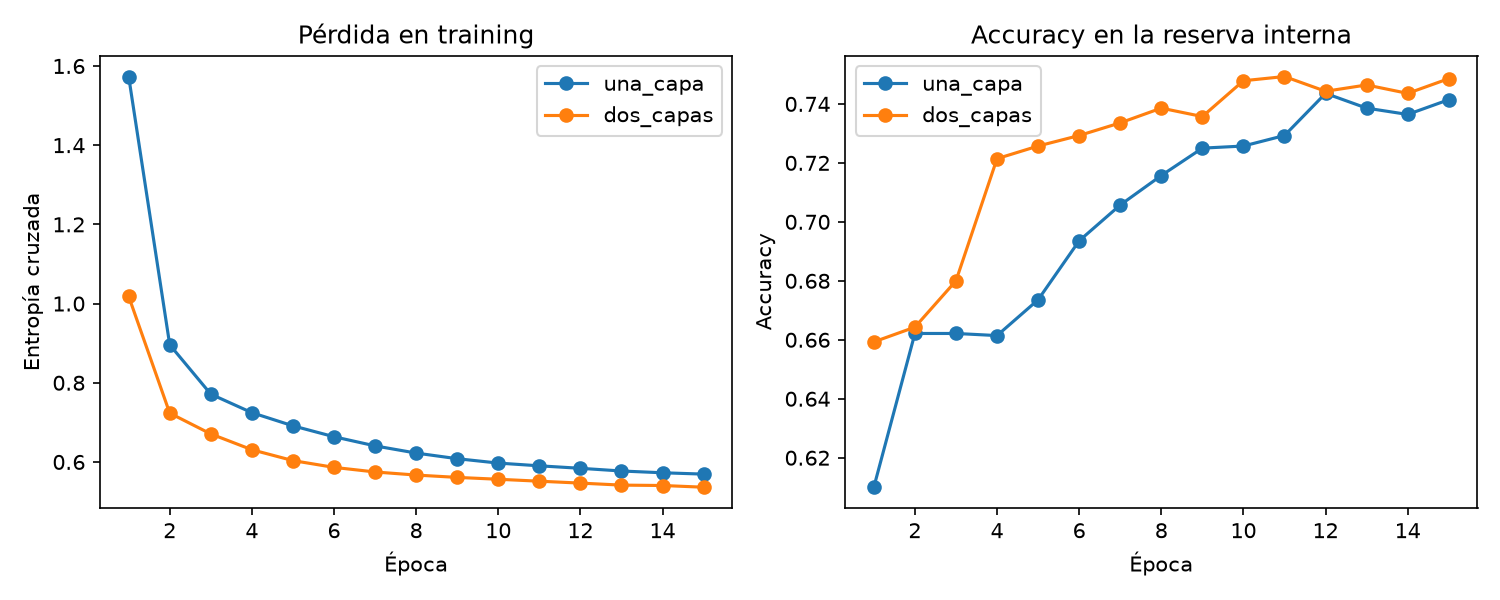

In [6]:
ejecutar("scripts.entrenar_red_neuronal", "--datos", datos, "--salida", red,
         "--epocas", 15, "--trabajos", 2, "--verbose")
display(pd.read_csv(red / "comparacion_validation.csv"))
display(Image(filename=str(red / "curvas_aprendizaje.png")))

## 3. Entrenar el árbol de decisión

El árbol de decisión fue el método con mayor F1 macro de validación en el informe del TP. En esta demo se ajustan sus dos variantes sobre la muestra y se selecciona una con el mismo criterio.

In [7]:
ejecutar("scripts.entrenar_arboles", "--metodo", "arbol_decision",
         "--datos", datos, "--salida", corrida)
display(pd.read_csv(arbol / "comparacion_validation.csv"))

Entrenando arbol_decision/sin_pesos: 14,000 filas
Resultado arbol_decision: {'variante': 'sin_pesos', 'segundos_ajuste': 0.20588590000988916, 'accuracy': 0.707, 'f1_macro': 0.41653943746373584, 'balanced_accuracy': 0.40894070740966715, 'f1_weighted': 0.7076054417488283, 'f1_macro_train': 0.5751150176450154}
Entrenando arbol_decision/balanceada: 14,000 filas
Resultado arbol_decision: {'variante': 'balanceada', 'segundos_ajuste': 0.17651969997677952, 'accuracy': 0.6333333333333333, 'f1_macro': 0.400269589307376, 'balanced_accuracy': 0.4719741542946241, 'f1_weighted': 0.6541005590392345, 'f1_macro_train': 0.5978485773679512}


,variante,segundos_ajuste,accuracy,f1_macro,balanced_accuracy,f1_weighted,f1_macro_train
0,sin_pesos,0.205886,0.707000,0.416539,0.408941,0.707605,0.575115
1,balanceada,0.176520,0.633333,0.400270,0.471974,0.654101,0.597849


## 4. Cargar y evaluar los modelos guardados

La comparación usa toda la partición de prueba. La matriz de confusión del árbol muestra cuántos casos de cada severidad se clasificaron correctamente y hacia qué clases se desviaron los errores.

,Modelo,Variante,Accuracy,F1 macro,Balanced accuracy
0,Red neuronal,dos_capas,0.7407,0.3757,0.3669
1,Árbol de decisión,sin_pesos,0.7147,0.4112,0.4038


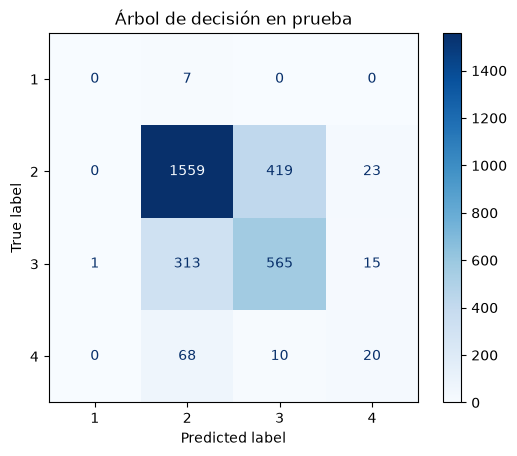

In [8]:
x_test = load_npz(datos / "X_test.npz").astype("float32")
y_test = pd.read_csv(datos / "y_test.csv")["Severity"]

modelos = {}
predicciones = {}
metricas = []
for nombre, carpeta in (("Red neuronal", red), ("Árbol de decisión", arbol)):
    experimento = json.loads((carpeta / "experimento.json").read_text(encoding="utf-8"))
    variante = experimento["seleccion"]["variante"]
    modelo = joblib.load(carpeta / variante / "modelo.joblib")
    modelos[nombre] = modelo
    prediccion = modelo.predict(x_test)
    predicciones[nombre] = prediccion
    metricas.append({
        "Modelo": nombre,
        "Variante": variante,
        "Accuracy": accuracy_score(y_test, prediccion),
        "F1 macro": f1_score(y_test, prediccion, labels=clases, average="macro", zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_test, prediccion),
    })

display(pd.DataFrame(metricas).round(4))
ConfusionMatrixDisplay.from_predictions(
    y_test, predicciones["Árbol de decisión"], labels=clases, cmap="Blues",
)
plt.title("Árbol de decisión en prueba")
plt.show()

## 5. Probar un accidente durante la presentación

La tabla sugiere un caso de prueba por severidad disponible. Cambiá `indice` en la última celda por un índice de la tabla o por cualquier otro índice válido para ver la predicción de ambos modelos.

In [29]:
casos = y_test.groupby(y_test).sample(n=3, random_state=42)
display(pd.DataFrame({
    "Severidad real": casos,
    **{nombre: prediccion[casos.index] for nombre, prediccion in predicciones.items()},
}).rename_axis("Índice de prueba"))

,Severidad real,Red neuronal,Árbol de decisión
Índice de prueba,,,
148,1,2,2
252,1,2,2
1797,1,2,2
2937,2,2,2
781,2,2,2
572,2,2,2
1206,3,3,3
1282,3,3,2
851,3,2,2


In [41]:
indice = int(1)
if not 0 <= indice < len(y_test):
    raise ValueError(f"Elegí un índice entre 0 y {len(y_test) - 1}.")

print(f"Caso {indice} | Severidad real: {y_test.iloc[indice]}")
display(pd.DataFrame([
    {"Modelo": nombre, "Severidad predicha": int(modelo.predict(x_test[indice])[0])}
    for nombre, modelo in modelos.items()
]))

Caso 1 | Severidad real: 2


,Modelo,Severidad predicha
0,Red neuronal,2
1,Árbol de decisión,3
